In [1]:
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker # used for percentage ticks
import matplotlib.colors as mcolors

# Stats
from scipy.stats import linregress
import statsmodels.formula.api as smf

In [2]:
from analysis import *

There are 3 real clones that have < 2 observation times.


## Linear Model

In [18]:
def linear_model(df, dep_var, scenario, duplicate):
    """
    This function fits a linear model relating a dependent variable (usually symlog
    drift rate) to the initial frequency of clones. This function fits the model on
    only one simulation scenario.

    This model does NOT fit the mixed linear model discussed in the Methods section. For that,
    scroll down to later in this notebook.
    """
    df2 = df.query('scenario == @scenario and ~r_opt.isna() and duplicate == @duplicate').copy()
    slope, intercept, r, p, stderr = linregress(df2['init_freq'], df2[dep_var])

    return slope, intercept, r, p, stderr, df2

dep_var = 'symlog10_r'
scenario = 'full_pipeline'
slope, intercept, r, p, stderr, df2 = linear_model(df, dep_var, scenario, 0)

print(f'The p value for scenario \'{scenario}\' is p={p:.2e}.')

The p value for scenario 'full_pipeline' is p=1.62e-14.


In [4]:
def p_table(scenario):
    rows = []
    for duplicate in df[df['scenario'] == scenario]['duplicate'].unique():
        slope, intercept, r, p, stderr, df2 = linear_model(df, 'symlog10_r', scenario, duplicate)
        row = {'Duplicate': duplicate, 'p': p}
        rows.append(row)
    
    results_df = pd.DataFrame(rows)
    return results_df

In [5]:
# Fit the linear model over 10 different runs of the model.
# You can change the scenario input to see how different simulations affect the p value.
# For example, input 'r36_rp3_mimic' to see the results for simulations with drift rate 3.
p_table('r36_rp2_mimic')

,Duplicate,p
0,0,0.322882
1,1,0.936698
2,2,0.459886
3,3,0.520517
4,4,0.229451
5,5,0.034648
6,6,0.376984
7,7,0.938196
8,8,0.744992
9,9,0.370299


## Generate Figure Plot

In [15]:
def panel(ax, df, scenario, label, duplicate, color):
    duplicate = 0
    slope, intercept, r, p, stderr, df2 = linear_model(df, 'symlog10_r', scenario, duplicate)
    
    x = np.linspace(0, 1, 200)
    y = intercept + slope * x

    ax.plot(x, y, color = 'black', linewidth = 2)
    ax.scatter(df2['init_freq'], df2[dep_var], color = palette[label], alpha=0.8,
                  edgecolor='black', linewidth=0.5, s = 15)
    
    ax.set_title(label)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
    # ax.text(0.95, 0.1, format_p(p),
    #          transform=ax.transAxes, ha='right', va='bottom', fontsize=6)
    ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray')
    ax.set_axisbelow(True) 
    ax.set_xlim([0, 1])

In [16]:
def format_p(p):
    if p < 1e-3:
        mantissa, exponent = f"{p:.2e}".split("e")
        exponent = int(exponent)
        return rf"$p = {mantissa} \times 10^{{{exponent}}}$"
    else:
        return rf"$p = {p:.2g}$"

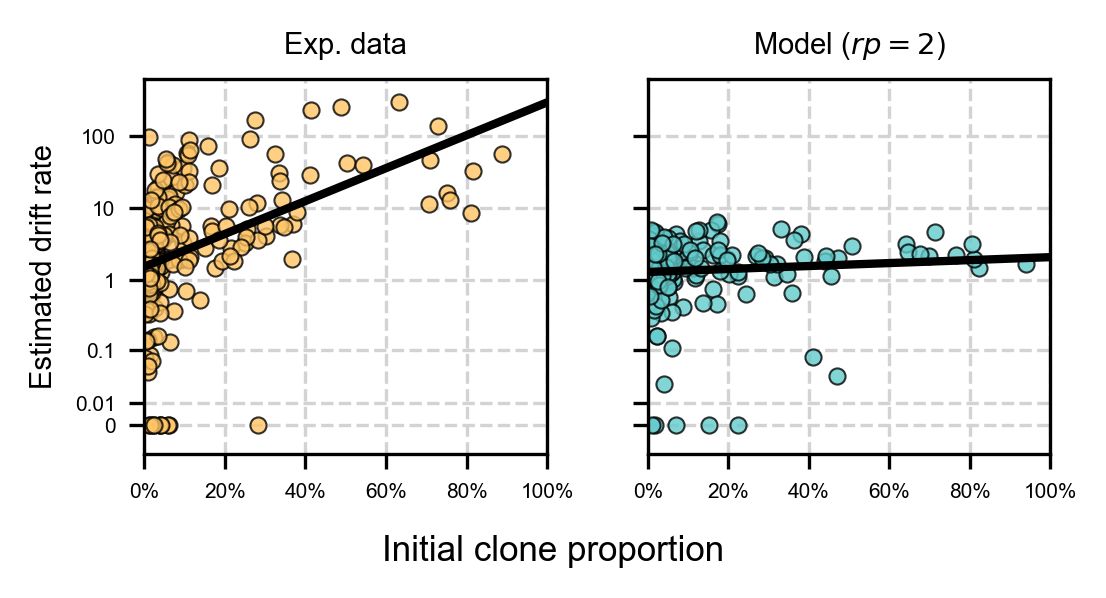

In [24]:
plt.rcParams.update(small_label_settings)

supplement_mode = False

if supplement_mode:
    scenarios = ['full_pipeline', 'full_pipeline_TQ14', 'full_pipeline_MP0.95', 'no_cluster', 'r36_rp2_mimic']
    labels = ['Exp. data', 'Exp. data (TQ 14)', 'Exp. data (MP 0.95)', 'Exp. data (no cluster)', 'Model ($rp=2$)']
    fig, ax = plt.subplots(1, 5, figsize = (6.5, 1.5), dpi = 300, sharey = True)    
    filepath = os.path.join('images', 'correlation_supplement.svg')
else:
    scenarios = ['full_pipeline', 'r36_rp2_mimic']
    labels = ['Exp. data', 'Model ($rp=2$)']
    fig, ax = plt.subplots(1, 2, figsize = (3.7, 2), dpi = 300, sharey = True)    
    filepath = os.path.join('images', 'correlation.svg')

for i, (scenario, label) in enumerate(zip(scenarios, labels)):
    duplicate = 0
    panel(ax[i], df, scenario, label, duplicate, palette[label])

ax[0].set_ylabel("Estimated drift rate")

tick_r = [0, 1e-2, 1e-1, 1, 10, 100]
ax[0].set_ylim([-0.4, 4.8])
tick_symlog = symlog10(np.array(tick_r), linthresh=1e-2)
ax[0].set_yticks(tick_symlog)
ax[0].set_yticklabels([str(r) for r in tick_r])

fig.supxlabel("Initial clone proportion", y = 0.05)

plt.tight_layout()
plt.subplots_adjust(wspace=0.25)   # smaller = tighter spacing

plt.savefig(filepath, bbox_inches = 'tight', pad_inches = 0)

## Linear Mixed Model
Below are linear models that fit a line to both simulated and experimental data with an interaction term. This is not discussed in the paper but has a similar result as the earlier linear models: the model does not significantly depend on initial clone size but the interaction term is significant.

In [9]:
def linear_mm(df, exp_scenario, sim_scenario, sim_duplicate):
    df2 = df[
        (df['scenario'] == exp_scenario) |
        ((df['scenario'] == sim_scenario) & (df['duplicate'] == sim_duplicate))
    ].copy()

    # Set scenario as categorial and re-order.
    df2['scenario'] = pd.Categorical(df2['scenario'])
    df2['scenario'] = df2['scenario'].cat.reorder_categories(
        [sim_scenario, exp_scenario]
    )
    
    # Center data
    df2['init_freq_c'] = df2['init_freq']  - df2['init_freq'].mean()
    df2['log_r_c']     = df2['symlog10_r'] - df2['symlog10_r'].mean()

    model = smf.mixedlm(
        "log_r_c ~ init_freq_c * scenario",
        data=df2,
        groups=df2["fish"],
        re_formula="~1"
    ).fit(method="lbfgs")
    return model, df2

In [10]:
exp_scenario = 'full_pipeline'
sim_scenario = 'r36_rp2_mimic'

model, df2 = linear_mm(df, exp_scenario, sim_scenario, 0)
model.summary()

/opt/anaconda3/envs/weber/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


<class 'statsmodels.iolib.summary2.Summary'>
"""
                     Mixed Linear Model Regression Results
================================================================================
Model:                     MixedLM         Dependent Variable:         log_r_c  
No. Observations:          447             Method:                     REML     
No. Groups:                24              Scale:                      0.3907   
Min. group size:           5               Log-Likelihood:             -441.2829
Max. group size:           29              Converged:                  Yes      
Mean group size:           18.6                                                 
--------------------------------------------------------------------------------
                                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------------
Intercept                             -0.142    0.068 -2.080 0.037 -0.275 -0.008
scenario[T.full_pipeline]              0.282    0.062  4.540 0.000  0.160  0.404
init_freq_c                            0.140    0.253  0.552 0.581 -0.356  0.635
init_freq_c:scenario[T.full_pipeline]  2.114    0.345  6.129 0.000  1.438  2.790
Group Var                              0.050    0.035                           
================================================================================

"""

In [11]:
print(f"The significance of initial frequency on simulated data is {model.pvalues['init_freq_c']:.3g}.")
print(f"The significance of interaction on initial frequency is {model.pvalues['init_freq_c:scenario[T.full_pipeline]']:.3g}.")

The significance of initial frequency on simulated data is 0.581.
The significance of interaction on initial frequency is 8.82e-10.


In [22]:
exp_scenario = 'full_pipeline'
sim_scenario = 'r36_rp2_mimic'

rows = []
for d in range(10):
    model, df2 = linear_mm(df, exp_scenario, sim_scenario, d)
    interact_p = model.pvalues[f'init_freq_c:scenario[T.{exp_scenario}]']
    sim_p = model.pvalues['init_freq_c']
    
    # print(f'For duplicate {d}, the simulation p is {sim_p:.3g} and the interaction p is {interact_p:.3g}.')
    row = {'Duplicate': d, 'simulation p': sim_p, 'interaction p': interact_p}
    rows.append(row)

results_df = pd.DataFrame(rows)
results_df

/opt/anaconda3/envs/weber/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/weber/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/weber/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/weber/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/weber/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/weber/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: User

,Duplicate,simulation p,interaction p
0,0,0.580648,8.816944e-10
1,1,0.735801,4.487858e-11
2,2,0.739044,3.937585e-10
3,3,0.456989,1.651018e-12
4,4,0.503294,4.625945e-09
5,5,0.032666,8.264640e-15
6,6,0.377174,8.459173e-12
7,7,0.661688,2.229747e-11
8,8,0.683726,2.143472e-11
9,9,0.723931,2.170667e-09
